In [1]:
%pip install hitran-api numpy pandas matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


HAPI version: 1.3.0.0
To get the most up-to-date version please check http://hitran.org/hapi
ATTENTION: Python versions of partition sums from TIPS-2021 are now available in HAPI code

           MIT license: Copyright 2021 HITRAN team, see more at http://hitran.org. 

           If you use HAPI in your research or software development,
           please cite it using the following reference:
           R.V. Kochanov, I.E. Gordon, L.S. Rothman, P. Wcislo, C. Hill, J.S. Wilzewski,
           HITRAN Application Programming Interface (HAPI): A comprehensive approach
           to working with spectroscopic data, J. Quant. Spectrosc. Radiat. Transfer 177, 15-30 (2016)
           DOI: 10.1016/j.jqsrt.2016.03.005

           ATTENTION: This is the core version of the HITRAN Application Programming Interface.
                      For more efficient implementation of the absorption coefficient routine, 
                      as well as for new profiles, parameters and other functional,
      

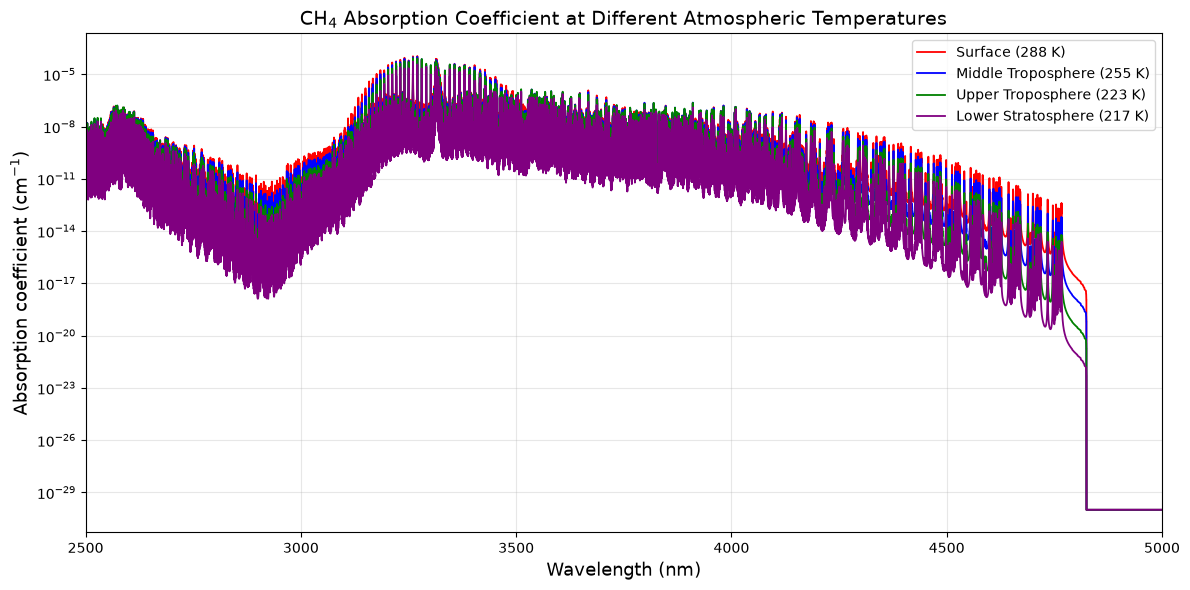

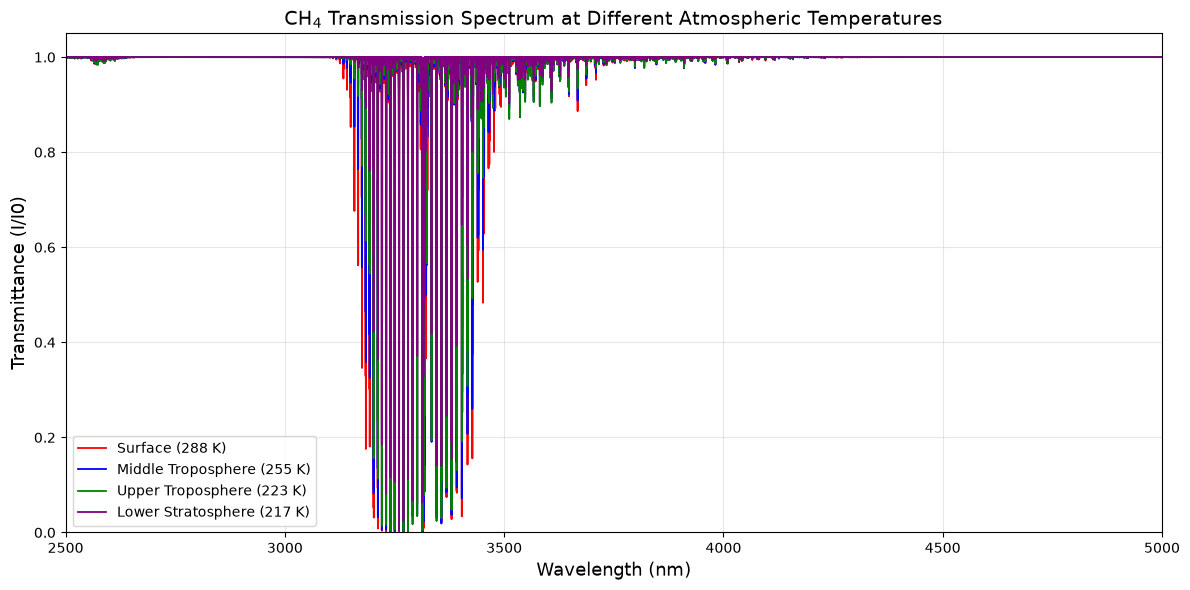

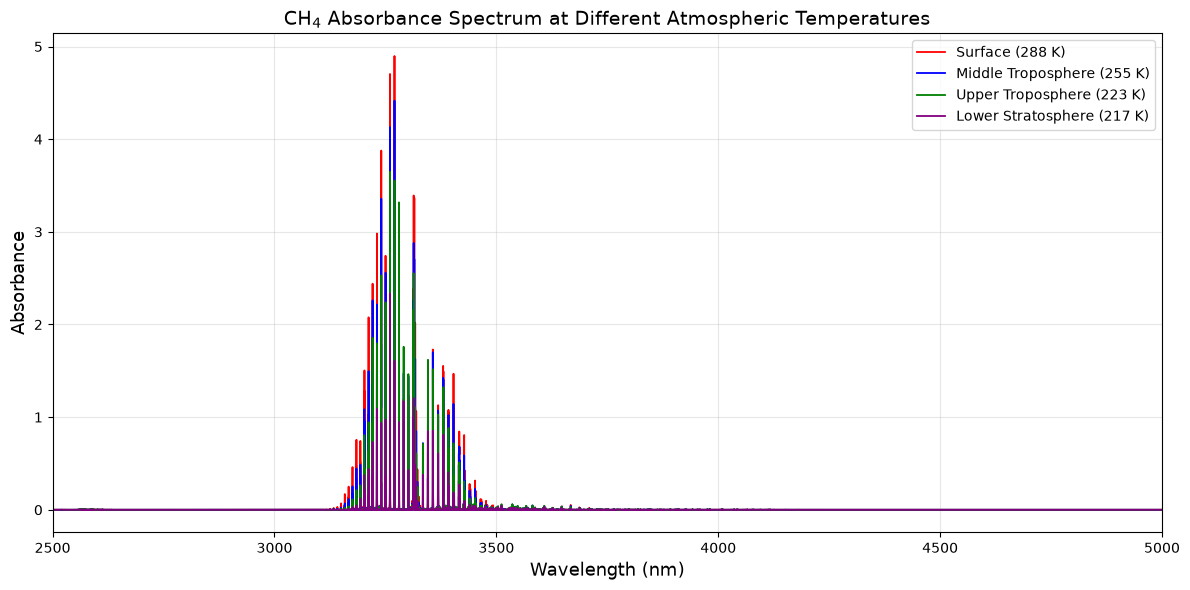


       SIMULATION SUCCESSFUL
Generated files:
1. CH4_Absorption_Coefficient.png
2. CH4_Transmission.png
3. CH4_Absorbance.png
4. CH4_Atmospheric_HITRAN_Data.csv

Selected atmospheric conditions:
Surface (288 K) | Temperature: 288 K | Pressure: 1013 hPa | CH4: 1.9 ppm
Middle Troposphere (255 K) | Temperature: 255 K | Pressure: 540 hPa | CH4: 1.9 ppm
Upper Troposphere (223 K) | Temperature: 223 K | Pressure: 265 hPa | CH4: 1.85 ppm
Lower Stratosphere (217 K) | Temperature: 217 K | Pressure: 55 hPa | CH4: 1.7999999999999998 ppm


In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hapi
from scipy.constants import Boltzmann

# =====================================================
# 1. CREATE HITRAN DATABASE
# =====================================================

DATABASE = "CH4_HITRAN_ATMOSPHERE"

os.makedirs(DATABASE, exist_ok=True)
hapi.db_begin(DATABASE)

# =====================================================
# 2. DOWNLOAD CH4 DATA FROM HITRAN
# =====================================================

# CH4 molecule ID = 6
# Main isotopologue ID = 1

nu_min = 2000.0
nu_max = 4000.0

TABLE = "CH4"

print("Checking HITRAN CH4 data...")

if TABLE not in hapi.tableList():

    print("Downloading CH4 data from HITRAN...")

    hapi.fetch(
        TABLE,
        6,
        1,
        nu_min,
        nu_max
    )

else:
    print("CH4 HITRAN data already exists.")

print("HITRAN data ready!")

# =====================================================
# 3. SELECTED ATMOSPHERIC CONDITIONS
# =====================================================

conditions = {

    "Surface (288 K)": {
        "T": 288,
        "P": 1013,
        "VMR": 1.90e-6
    },

    "Middle Troposphere (255 K)": {
        "T": 255,
        "P": 540,
        "VMR": 1.90e-6
    },

    "Upper Troposphere (223 K)": {
        "T": 223,
        "P": 265,
        "VMR": 1.85e-6
    },

    "Lower Stratosphere (217 K)": {
        "T": 217,
        "P": 55,
        "VMR": 1.80e-6
    }
}

# =====================================================
# 4. PHYSICAL PARAMETERS
# =====================================================

# Optical path length = 1 km
path_length_cm = 1.0e5

omega_step = 0.02
omega_wing = 25.0

spectra = {}

# =====================================================
# 5. HITRAN ABSORPTION CALCULATION
# =====================================================

for layer, condition in conditions.items():

    T = condition["T"]
    P_hPa = condition["P"]
    VMR = condition["VMR"]

    print(f"\nCalculating {layer}...")

    # Convert pressure into atm
    P_atm = P_hPa / 1013.25

    # Air and methane self-broadening fractions
    diluent = {
        "air": 1.0 - VMR,
        "self": VMR
    }

    # Calculate HITRAN absorption cross-section
    nu, sigma = hapi.absorptionCoefficient_Voigt(

        SourceTables=TABLE,

        Components=[(6, 1, 1.0)],

        Environment={
            "T": float(T),
            "p": float(P_atm)
        },

        Diluent=diluent,

        OmegaRange=(nu_min, nu_max),

        OmegaStep=omega_step,

        OmegaWing=omega_wing,

        # True gives cross-section in cm2/molecule
        HITRAN_units=True
    )

    nu = np.asarray(nu, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    if len(nu) == 0:
        raise RuntimeError(
            f"No HITRAN data returned for {layer}"
        )

    # =================================================
    # 6. METHANE NUMBER DENSITY
    # =================================================

    # Convert pressure into Pa
    P_Pa = P_hPa * 100.0

    # Total molecular number density (molecules/cm3)
    n_total = P_Pa / (Boltzmann * T) / 1e6

    # Methane number density (molecules/cm3)
    n_CH4 = n_total * VMR

    # Absorption coefficient:
    # alpha = cross-section * number density

    alpha = sigma * n_CH4

    # =================================================
    # 7. BEER-LAMBERT LAW
    # =================================================

    optical_depth = alpha * path_length_cm

    # Transmitted intensity
    transmission = np.exp(
        -np.clip(optical_depth, 0, 700)
    )

    # Decadic absorbance
    absorbance = optical_depth / np.log(10)

    # Fraction of incident radiation absorbed
    absorption_fraction = 1 - transmission

    # =================================================
    # 8. CONVERT WAVENUMBER TO WAVELENGTH (nm)
    # =================================================

    wavelength_nm = 1e7 / nu

    # Sort wavelength in ascending order
    order = np.argsort(wavelength_nm)

    wavelength_nm = wavelength_nm[order]
    alpha = alpha[order]
    transmission = transmission[order]
    absorbance = absorbance[order]
    absorption_fraction = absorption_fraction[order]

    spectra[layer] = {

        "wavelength": wavelength_nm,
        "alpha": alpha,
        "transmission": transmission,
        "absorbance": absorbance,
        "absorption_fraction": absorption_fraction
    }

    print(
        "Maximum absorption coefficient:",
        np.max(alpha)
    )

    print(
        "Maximum absorbance:",
        np.max(absorbance)
    )

print("\nAll atmospheric calculations completed!")

# =====================================================
# 9. GRAPH 1: ABSORPTION COEFFICIENT
# =====================================================

plt.figure(figsize=(12, 6))

colors = ["red", "blue", "green", "purple"]

for (layer, color) in zip(conditions, colors):

    wavelength = spectra[layer]["wavelength"]
    alpha = spectra[layer]["alpha"]

    plt.plot(
        wavelength,
        np.maximum(alpha, 1e-30),
        color=color,
        label=layer,
        linewidth=1.3
    )

plt.xlabel("Wavelength (nm)", fontsize=13)

plt.ylabel(
    "Absorption coefficient (cm$^{-1}$)",
    fontsize=13
)

plt.title(
    "CH$_4$ Absorption Coefficient at Different Atmospheric Temperatures",
    fontsize=14
)

plt.yscale("log")
plt.xlim(2500, 5000)

plt.legend()
plt.grid(alpha=0.3, which="both")
plt.tight_layout()

plt.savefig(
    "CH4_Absorption_Coefficient.png",
    dpi=300
)

plt.show()

# =====================================================
# 10. GRAPH 2: TRANSMISSION SPECTRUM
# =====================================================

plt.figure(figsize=(12, 6))

for (layer, color) in zip(conditions, colors):

    plt.plot(
        spectra[layer]["wavelength"],
        spectra[layer]["transmission"],
        color=color,
        label=layer,
        linewidth=1.3
    )

plt.xlabel("Wavelength (nm)", fontsize=13)

plt.ylabel("Transmittance (I/I0)", fontsize=13)

plt.title(
    "CH$_4$ Transmission Spectrum at Different Atmospheric Temperatures",
    fontsize=14
)

plt.xlim(2500, 5000)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "CH4_Transmission.png",
    dpi=300
)

plt.show()

# =====================================================
# 11. GRAPH 3: ABSORBANCE SPECTRUM
# =====================================================

plt.figure(figsize=(12, 6))

for (layer, color) in zip(conditions, colors):

    plt.plot(
        spectra[layer]["wavelength"],
        spectra[layer]["absorbance"],
        color=color,
        label=layer,
        linewidth=1.3
    )

plt.xlabel("Wavelength (nm)", fontsize=13)

plt.ylabel("Absorbance", fontsize=13)

plt.title(
    "CH$_4$ Absorbance Spectrum at Different Atmospheric Temperatures",
    fontsize=14
)

plt.xlim(2500, 5000)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "CH4_Absorbance.png",
    dpi=300
)

plt.show()

# =====================================================
# 12. SAVE ALL RESULTS IN CSV FILE
# =====================================================

data = {
    "Wavelength_nm":
        spectra[list(conditions.keys())[0]]["wavelength"]
}

for layer in conditions:

    label = (
        layer.replace(" ", "_")
             .replace("(", "")
             .replace(")", "")
    )

    data[f"Absorption_{label}_cm-1"] = (
        spectra[layer]["alpha"]
    )

    data[f"Transmission_{label}"] = (
        spectra[layer]["transmission"]
    )

    data[f"Absorbance_{label}"] = (
        spectra[layer]["absorbance"]
    )

df = pd.DataFrame(data)

df.to_csv(
    "CH4_Atmospheric_HITRAN_Data.csv",
    index=False
)

# =====================================================
# 13. FINAL OUTPUT
# =====================================================

print("\n====================================")
print("       SIMULATION SUCCESSFUL")
print("====================================")

print("Generated files:")

print("1. CH4_Absorption_Coefficient.png")
print("2. CH4_Transmission.png")
print("3. CH4_Absorbance.png")
print("4. CH4_Atmospheric_HITRAN_Data.csv")

print("\nSelected atmospheric conditions:")

for layer, condition in conditions.items():

    print(
        layer,
        "| Temperature:", condition["T"], "K",
        "| Pressure:", condition["P"], "hPa",
        "| CH4:", condition["VMR"] * 1e6, "ppm"
    )
